# Bench F: current-to-voltage clamp cell (Fig. 14)

XM3 (NMOS, linear region) is the transresistance from the delta-I node `di` to V_MID. XM2 (PMOS diode at V_MID) sets the gate of the clamp XM1, which conducts only once `di` rises above V_MID by the body-effect threshold difference. `Iin` is positive into `di`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sarlib import specs as S
from sarlib.analysis import load_cols, parse_op_log, eng, log_cross, window_around, settle_time, Report

DATA = Path('simulation/iv_clamp_tb.sch')
cl = S.clamp
SP = cl.SPECS
LSB = S.I_LSB
WIN = (cl.NODE_WINDOW[0] + cl.WINDOW_MARGIN, cl.NODE_WINDOW[1] - cl.WINDOW_MARGIN)
R_MIN = SP['vd_half_mv_min'] * 1e-3 / LSB
in_win = lambda *vs: all(WIN[0] <= x <= WIN[1] for x in vs)
rep = Report()

## Operating point at Iin = 0

In [2]:
vals = parse_op_log(DATA / 'op_f.log')
DEV = {'XM3': 'm.xc.xm3.msky130_fd_pr__nfet_01v8', 'XM2': 'm.xc.xm2.msky130_fd_pr__pfet_01v8_lvt',
       'XM1': 'm.xc.xm1.msky130_fd_pr__pfet_01v8_lvt'}
op = pd.DataFrame({d: {k: vals[f'@{p}[{k}]'] for k in ('vds', 'vdsat', 'vth', 'gm', 'id')} for d, p in DEV.items()}).T
v0_shift = vals['v(di)'] - S.VMID
xm3_lin = abs(op.loc['XM3', 'vds']) < abs(op.loc['XM3', 'vdsat'])
dvth = abs(op.loc['XM1', 'vth']) - abs(op.loc['XM2', 'vth'])
print(f"V(di) = {vals['v(di)']:.4f} V; clamp quiescent current {eng(vals['imid'] - cl.IB, 'A')}")
rep.check('XM3 in the linear region at Iin = 0', 'yes' if xm3_lin else 'no', 'yes', xm3_lin)
rep.check('V(di) at Iin = 0 vs V_MID', f'{1e3 * v0_shift:+.1f} mV', f"|.| <= {SP['v0_shift_mv_max']:g} mV", abs(v0_shift) <= 1e-3 * SP['v0_shift_mv_max'])
rep.info('|Vth1| - |Vth2|', f'{1e3 * dvth:.0f} mV')
op

V(di) = 0.8997 V; clamp quiescent current 8.24 nA


,vds,vdsat,vth,gm,id
XM3,-0.000275,0.186404,0.719977,4.849627e-08,8.245000e-09
XM2,0.392560,0.054393,0.443870,8.958171e-06,4.999996e-07
XM1,0.899724,0.042330,0.659284,2.216406e-07,8.235915e-09


## Transfer curve V(Iin)

XM1 current from KCL: I_XM1 = Iin + (I_VMID − Ib).

R0 33 kohm (needed 32 kohm), Vd(0.5 LSB) 5.16 mV
+/-10 uA: V = 0.706 / 1.191 V, slope 9.37 kohm, XM1 takes 71 %
+/-20 uA: V = 0.584 / 1.258 V, slope 5.15 kohm, XM1 takes 85 %
clamp conducts 1 uA at V = 1.085 V (Iin = 3.85 uA)


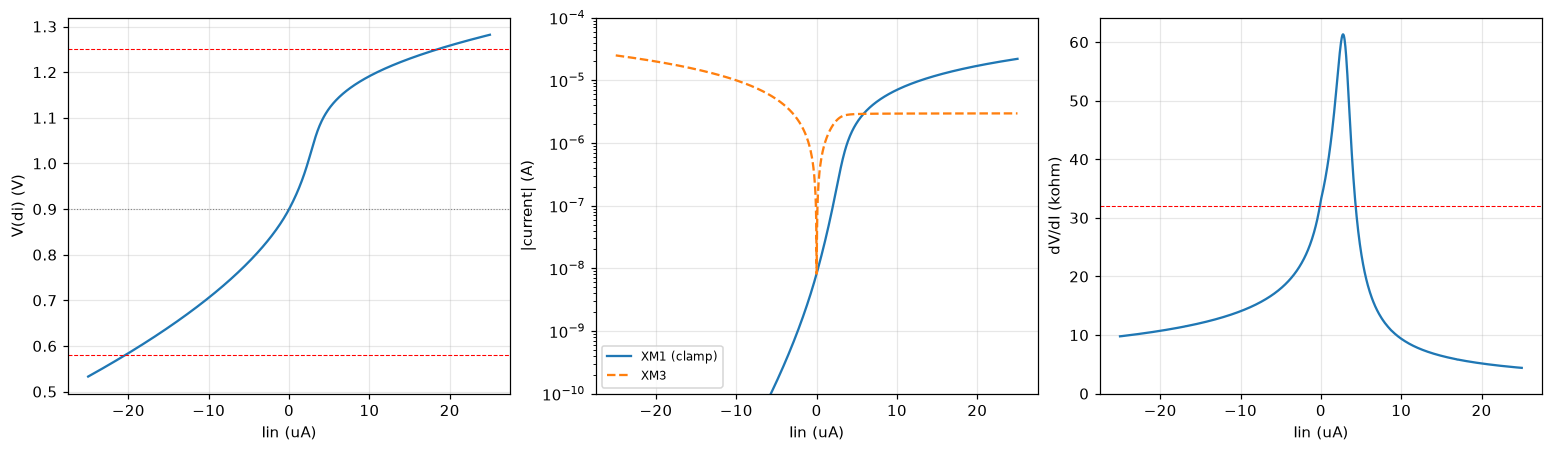

In [3]:
I, c = load_cols(DATA / 'dc_i.csv', ['vdi', 'imid'])
o = np.argsort(I)
I, V, i1 = I[o], c['vdi'][o], I[o] + c['imid'][o] - cl.IB
xf, cf = load_cols(DATA / 'dc_fine.csv', ['vdi', 'imid'])
f = lambda i: float(np.interp(i, I, V))
ff = lambda i: float(np.interp(i, np.sort(xf), cf['vdi'][np.argsort(xf)]))
vd_half = ff(0.5 * LSB) - ff(-0.5 * LSB)
r0 = vd_half / LSB
slope = np.gradient(V, I)
min_slope = slope[np.abs(I) <= cl.I_SAR].min() / r0
leak = float(np.interp(0.0, I, i1))
pts = {tag: (f(-i), f(i), float(np.interp(i, I, slope)), float(np.interp(i, I, i1)) / i) for tag, i in (('sar', cl.I_SAR), ('over', cl.I_OVER))}
on = np.where(i1 >= cl.CLAMP_ON)[0][0]
print(f'R0 {eng(r0, "ohm")} (needed {eng(R_MIN, "ohm")}), Vd(0.5 LSB) {1e3 * vd_half:.2f} mV')
for tag, i in (('sar', cl.I_SAR), ('over', cl.I_OVER)):
    vm, vp, sl, share = pts[tag]
    print(f'+/-{eng(i, "A")}: V = {vm:.3f} / {vp:.3f} V, slope {eng(sl, "ohm")}, XM1 takes {100 * share:.0f} %')
print(f'clamp conducts {eng(cl.CLAMP_ON, "A")} at V = {V[on]:.3f} V (Iin = {eng(I[on], "A")})')
rep.check('voltage for 0.5 LSB of error (single node)', f'{1e3 * vd_half:.2f} mV ({eng(r0, "ohm")})', f">= {SP['vd_half_mv_min']:g} mV",
          vd_half >= 1e-3 * SP['vd_half_mv_min'])
rep.check('quiescent clamp current', f'{leak / LSB:.3f} LSB', f"|.| <= {SP['leak_lsb_max']:g} LSB", abs(leak / LSB) <= SP['leak_lsb_max'])
rep.check('monotonic', 'yes' if np.all(slope > 0) else 'no', 'yes', bool(np.all(slope > 0)))
rep.check(f'smallest slope for |Iin| <= {eng(cl.I_SAR, "A")}', f'{100 * min_slope:.1f} % of R0', f">= {100 * SP['min_slope_frac']:g} %",
          min_slope >= SP['min_slope_frac'])
rep.check(f'node inside {WIN[0]:.2f}-{WIN[1]:.2f} V at +/-{eng(cl.I_SAR, "A")}', '{:.3f} / {:.3f} V'.format(*pts['sar'][:2]), 'yes', in_win(*pts['sar'][:2]))
rep.info(f'node at +/-{eng(cl.I_OVER, "A")}', '{:.3f} / {:.3f} V'.format(*pts['over'][:2]))

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].plot(1e6 * I, V); [ax[0].axhline(w, c='r', lw=0.7, ls='--') for w in WIN]; ax[0].axhline(S.VMID, c='gray', lw=0.7, ls=':')
ax[0].set(xlabel='Iin (uA)', ylabel='V(di) (V)')
ax[1].semilogy(1e6 * I, np.maximum(np.abs(i1), 1e-12), label='XM1 (clamp)')
ax[1].semilogy(1e6 * I, np.maximum(np.abs(c['imid'][o] - cl.IB), 1e-12), '--', label='XM3')
ax[1].set(xlabel='Iin (uA)', ylabel='|current| (A)', ylim=(1e-10, 1e-4)); ax[1].legend(fontsize=8)
ax[2].plot(1e6 * I, 1e-3 * slope); ax[2].axhline(1e-3 * R_MIN, c='r', lw=0.7, ls='--')
ax[2].set(xlabel='Iin (uA)', ylabel='dV/dI (kohm)', ylim=(0, None))
plt.show()

## V_GATE and V_MID sweeps

R around zero (slope over ±0.25 uA) and the node at ±I_SAR; a point is ok when R ≥ R_MIN and the node stays in the window.

In [4]:
def group_sweep(name, key):
    x, c = load_cols(DATA / name, ['vdi', 'imid', key])
    rows = []
    for val in np.unique(np.round(c[key], 6)):
        k = np.isclose(c[key], val, atol=1e-6)
        o = np.argsort(x[k])
        g = lambda i: float(np.interp(i, x[k][o], c['vdi'][k][o]))
        r = (g(0.25e-6) - g(-0.25e-6)) / 0.5e-6
        vm, vp = g(-cl.I_SAR), g(cl.I_SAR)
        rows.append({key: val, 'R0': r, 'v(-I_SAR)': vm, 'v(+I_SAR)': vp, 'ok': bool(r >= R_MIN and in_win(vm, vp))})
    return pd.DataFrame(rows)

for name, key, nominal in (('dc_vg.csv', 'vg', cl.VGATE), ('dc_vm.csv', 'vm', S.VMID)):
    df = group_sweep(name, key)
    w = window_around(df[key].values, df['ok'].values, nominal)
    label = {'vg': 'V_GATE', 'vm': 'V_MID'}[key]
    rep.check(f'{label} range where R and the window pass', 'none' if w is None else f'{w[0]:.2f} to {w[1]:.2f} V',
              f'contains {nominal:g} V', w is not None)
    display(df.round(4))

,vg,R0,v(-I_SAR),v(+I_SAR),ok
0,1.40,650181.394,0.4222,1.2155,False
1,1.45,565742.634,0.4635,1.2155,False
2,1.50,480374.866,0.5045,1.2154,False
3,1.55,392908.006,0.5451,1.2153,False
4,1.60,297917.008,0.5842,1.2147,True
5,1.65,144632.212,0.6206,1.2132,True
6,1.70,72715.728,0.6532,1.2095,True
7,1.75,45956.156,0.6815,1.2025,True
8,1.80,32914.590,0.7057,1.1912,True


,vm,R0,v(-I_SAR),v(+I_SAR),ok
0,0.60,11068.184,0.4996,0.7268,False
1,0.65,12388.194,0.5403,0.7974,False
2,0.70,14095.620,0.5791,0.8767,False
3,0.75,16390.600,0.6157,0.9661,False
4,0.80,19640.180,0.6495,1.0541,False
5,0.85,24586.232,0.6798,1.1286,False
6,0.90,32914.590,0.7057,1.1912,True
7,0.95,49027.176,0.7264,1.2458,True
8,1.00,86637.020,0.7414,1.2946,False
9,1.05,190767.500,0.7506,1.3394,False


## Small signal

In [5]:
rows = []
for lab, (name, ib) in {'Iin = 0': ('ac_0.csv', 0.0), 'Iin = +5 uA': ('ac_p5.csv', 5e-6), 'Iin = -5 uA': ('ac_m5.csv', -5e-6)}.items():
    fr, c = load_cols(DATA / name, ['zdb', 'zph'])
    z0 = 10 ** (c['zdb'][0] / 20)
    r_dc = float(np.interp(ib, I, slope))
    rows.append(dict(bias=lab, z0=z0, r_dc=r_dc, mismatch_pct=100 * (z0 / r_dc - 1), f3db=log_cross(fr, c['zdb'], c['zdb'][0] - 3.0103),
                     f3db_expected=1 / (2 * np.pi * z0 * S.C_NODE), peaking_db=float(c['zdb'].max() - c['zdb'][0])))
AC = pd.DataFrame(rows).set_index('bias')
rep.check('ac impedance vs dc slope (worst bias)', f'{AC.mismatch_pct.abs().max():.1f} %', f"<= {SP['ac_dc_match_pct']:g} %",
          AC.mismatch_pct.abs().max() <= SP['ac_dc_match_pct'])
rep.info('-3 dB frequency at Iin = 0', eng(AC.f3db.iloc[0], 'Hz'))
rep.check('peaking (worst bias)', f'{AC.peaking_db.max():.2f} dB', f"<= {SP['peaking_db_max']:g} dB", AC.peaking_db.max() <= SP['peaking_db_max'])
AC.round(4)

,z0,r_dc,mismatch_pct,f3db,f3db_expected,peaking_db
bias,,,,,,
Iin = 0,33033.9259,33011.02,0.0694,1.959710e+07,4.817924e+07,0.0000
Iin = +5 uA,24118.9166,24121.80,-0.0120,4.686656e+07,6.598760e+07,0.0743
Iin = -5 uA,17948.4901,17948.60,-0.0006,3.260100e+07,8.867317e+07,0.0000


## Current-step transient

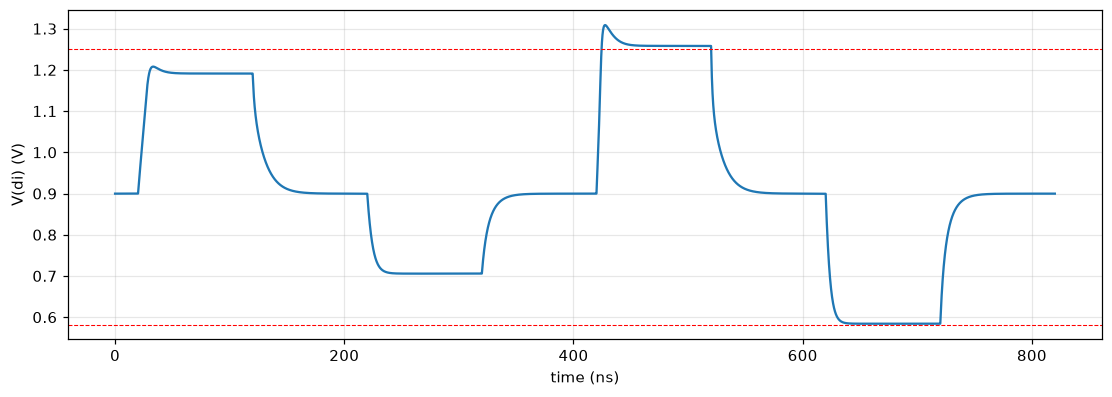

,step_mV,settle_ns,overshoot_mV,v_max,v_min,in_window
step,,,,,,
+0 -> +10 uA,291.441,27.233,16.726,1.208,0.900,True
+10 -> +0 uA,-291.434,44.220,0.003,1.191,0.900,True
+0 -> -10 uA,-194.062,18.119,0.000,0.900,0.706,True
-10 -> +0 uA,194.054,32.214,0.001,0.900,0.706,True
+0 -> +20 uA,358.462,29.400,50.488,1.309,0.900,False
+20 -> +0 uA,-358.454,44.028,0.003,1.258,0.900,False
+0 -> -20 uA,-315.571,16.007,0.000,0.900,0.584,True
-20 -> +0 uA,315.563,34.628,0.001,0.900,0.584,True


In [6]:
t, c = load_cols(DATA / 'tran.csv', ['vdi'])
v = c['vdi']
edges = [0.0] + [e[0] for e in cl.TRAN_EVENTS] + [t[-1]]
rows = []
for k, (te, i0, i1_) in enumerate(cl.TRAN_EVENTS):
    t_prev, t_next = edges[k], edges[k + 2]
    v0 = v[(t > te - 0.1 * (te - t_prev)) & (t < te)].mean()
    v1 = v[(t > t_next - 0.1 * (t_next - te)) & (t <= t_next)].mean()
    seg = (t >= te) & (t <= t_next)
    sgn = 1.0 if v1 >= v0 else -1.0
    rows.append(dict(step=f'{1e6 * i0:+.0f} -> {1e6 * i1_:+.0f} uA', i_max=max(abs(i0), abs(i1_)), step_mV=1e3 * (v1 - v0),
                     settle_ns=1e9 * settle_time(t[seg], v[seg], v1, cl.SETTLE_BAND, te),
                     overshoot_mV=1e3 * max(0.0, np.max(sgn * (v[seg] - v1))), v_max=v[seg].max(), v_min=v[seg].min(),
                     in_window=in_win(v[seg].max(), v[seg].min())))
TRAN = pd.DataFrame(rows).set_index('step')
sar_ok = bool(TRAN[TRAN.i_max <= cl.I_SAR + 1e-12].in_window.all())
rep.info('worst settling time', f'{TRAN.settle_ns.max():.1f} ns')
rep.info('worst overshoot', f'{TRAN.overshoot_mV.max():.1f} mV')
rep.check(f'node in the window in the +/-{eng(cl.I_SAR, "A")} steps', 'yes' if sar_ok else 'no', 'yes', sar_ok)
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(1e9 * t, v); [ax.axhline(w, c='r', ls='--', lw=0.7) for w in WIN]
ax.set(xlabel='time (ns)', ylabel='V(di) (V)')
plt.show()
TRAN.drop(columns='i_max').round(3)

## Summary

In [7]:
rep.table()

,check,value,spec,result
0,XM3 in the linear region at Iin = 0,yes,yes,PASS
1,V(di) at Iin = 0 vs V_MID,-0.3 mV,|.| <= 30 mV,PASS
2,|Vth1| - |Vth2|,215 mV,,INFO
3,voltage for 0.5 LSB of error (single node),5.16 mV (33 kohm),>= 5 mV,PASS
4,quiescent clamp current,0.053 LSB,|.| <= 0.1 LSB,PASS
5,monotonic,yes,yes,PASS
6,smallest slope for |Iin| <= 10 uA,28.4 % of R0,>= 3 %,PASS
7,node inside 0.58-1.25 V at +/-10 uA,0.706 / 1.191 V,yes,PASS
8,node at +/-20 uA,0.584 / 1.258 V,,INFO
9,V_GATE range where R and the window pass,1.60 to 1.80 V,contains 1.8 V,PASS
